# NOTEBOOK 01: TIỀN XỬ LÝ DỮ LIỆU PCA, THIẾT KẾ SƠ ĐỒ MẠCH & HUẤN LUYỆN MÔ HÌNH (TRAINING PIPELINE)
**Đề tài 2.7:** *Benchmarking quantum machine learning for detecting DDoS cyber-attacks: a NISQ-era evaluation*  
**Học phần:** Mã hóa và Mật mã học (CC102) — **Giảng viên hướng dẫn:** PGS. TS. Nguyễn Tấn Khôi  
**Sinh viên thực hiện:** Ngô Văn Công (102230284) & Nguyễn Công Minh (102230306)

---
### Mục tiêu của Notebook 01 (Giai đoạn Huấn luyện - Training):
1. **Nạp Tập dữ liệu Huấn luyện (`dataset/tr_day_syn_small.csv`):** Làm sạch, chuẩn hóa `MaxAbsScaler` về đoạn `[0, 1]` và giảm chiều bằng `PCA` từ 80 đặc trưng gốc xuống **8 thành phần chính (`PC1 -> PC8`)** tương ứng với **8 Qubits**.
2. **Thiết kế & Trực quan hóa Sơ đồ Mạch Lượng tử:** Xây dựng các khối nhúng dữ liệu (`Angle Embedding`, `Amplitude Embedding 3-Qubit`, `ZZ Feature Map`) và 2 kiến trúc mạng nơ-ron biến phân (`Two-Local 16 tham số`, `Tree-Tensor Network 15 tham số`).
3. **Huấn luyện toàn bộ 7 Mô hình (2 Classical + 3 QSVM + 2 QNN/VQC):** Đo đạc thời gian huấn luyện (`Train Time`) và độ chính xác trên tập huấn luyện (`Train Accuracy`).
4. **Lưu trữ (Export) Toàn bộ Model & Trọng số Lượng tử ra đĩa (`models/trained_qml_ddos_bundle.pkl`):** Phục vụ cho **Notebook 02 (`02_test_and_evaluate_qml_ddos.ipynb`)** nạp lên và kiểm thử độc lập mà không cần huấn luyện lại.

In [1]:
import os, sys, subprocess

# Tu dong nhan dien moi truong: Google Colab / Kaggle / May tram cuc bo
if "google.colab" in sys.modules or os.path.exists("/content"):
    if not os.path.exists("/content/qml-ddos"):
        subprocess.run(["git", "clone", "https://github.com/vcongggggg/qml-ddos.git", "/content/qml-ddos"], check=False)
    try:
        import pennylane
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pennylane", "joblib", "scikit-learn", "matplotlib", "seaborn"], check=False)
    BASE_DIR = "/content/qml-ddos"
elif os.path.exists(r"C:\Study\HocKy6\MH&MM\qml-ddos"):
    BASE_DIR = r"C:\Study\HocKy6\MH&MM\qml-ddos"
else:
    BASE_DIR = os.getcwd()

import time
import math
import warnings
from itertools import combinations
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MaxAbsScaler
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

import pennylane as qml
from pennylane import numpy as pnp

warnings.filterwarnings('ignore')

DATASET_DIR = os.path.join(BASE_DIR, "dataset")
MODELS_DIR = os.path.join(BASE_DIR, "models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

N_QUBITS = 8
PCA_COMPONENTS = 8
K_TTN = math.ceil(math.log2(N_QUBITS))
RANDOM_SEED = 1234
np.random.seed(RANDOM_SEED)

print(f"PennyLane version: {qml.__version__}")
print(f"Cấu hình lượng tử: {N_QUBITS} Qubits | Số thành phần PCA: {PCA_COMPONENTS} | Chiều sâu cây TTN K = {K_TTN}")

PennyLane version: 0.45.1
Cấu hình lượng tử: 8 Qubits | Số thành phần PCA: 8 | Chiều sâu cây TTN K = 3


---
## BƯỚC 1: Nạp Tập Dữ Liệu Huấn Luyện (`tr_day_syn_small.csv`), Chuẩn Hóa & Giảm Chiều PCA (80 -> 8 Chiều)
- Tập dữ liệu huấn luyện thu thập ngày `01-12` từ bộ `CICDDoS2019`.
- Nhãn `0`: Tấn công `Syn DDoS` | Nhãn `1`: Lưu lượng hợp lệ `Benign`.
- Bộ `MaxAbsScaler` và `PCA(n_components=8)` chỉ được `fit` trên tập Train, sau đó được lưu vào `models/` để áp dụng cho tập Test ở Notebook 02.

Kích thước dữ liệu gốc: (120, 79) -> Sau PCA: (120, 8)
Tổng lượng thông tin bảo toàn trên 8 Qubits: 91.21%

Qubit / Thành phần PCA  Phương sai đơn lẻ (%)  Phương sai tích lũy (%)
         Qubit 0 (PC1)                  53.20                    53.20
         Qubit 1 (PC2)                  11.02                    64.22
         Qubit 2 (PC3)                   7.49                    71.71
         Qubit 3 (PC4)                   6.33                    78.04
         Qubit 4 (PC5)                   4.50                    82.54
         Qubit 5 (PC6)                   3.72                    86.26
         Qubit 6 (PC7)                   2.71                    88.97
         Qubit 7 (PC8)                   2.24                    91.21


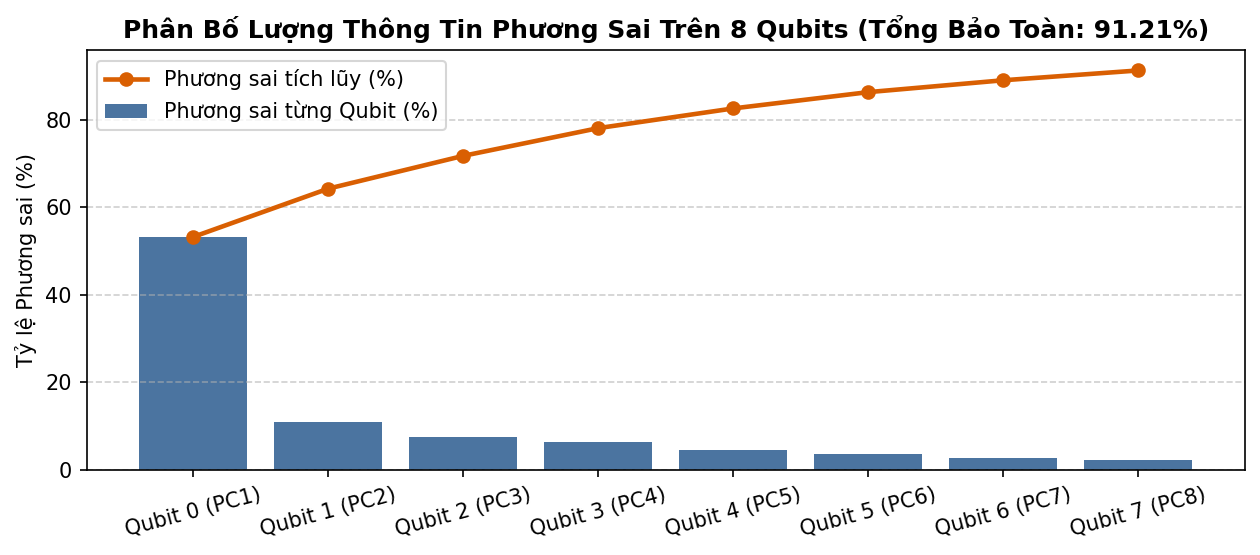

In [2]:
p_tr = os.path.join(DATASET_DIR, "tr_day_syn_small.csv")
df_tr = pd.read_csv(p_tr)
label_col = "Label" if "Label" in df_tr.columns else " Label"

# Lấy tập mẫu huấn luyện chuẩn (100 Syn : 20 Benign)
df_tr_0 = df_tr[df_tr[label_col] == 0].sample(n=100, random_state=RANDOM_SEED)
df_tr_1 = df_tr[df_tr[label_col] == 1].sample(n=20, random_state=RANDOM_SEED)
df_tr_sub = pd.concat([df_tr_0, df_tr_1]).sample(frac=1.0, random_state=RANDOM_SEED)

x_tr_raw = df_tr_sub.drop(columns=label_col).to_numpy()
y_tr = df_tr_sub[label_col].to_numpy().astype(int)

# 1. Fit MaxAbsScaler trên tập Train
scaler = MaxAbsScaler()
x_tr_scaled = scaler.fit_transform(x_tr_raw)

# 2. Fit PCA giảm từ 80 chiều xuống 8 chiều (8 Qubits)
pca = PCA(n_components=PCA_COMPONENTS, random_state=RANDOM_SEED)
xs_tr = pca.fit_transform(x_tr_scaled)

var_ratios = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(var_ratios)

pca_df = pd.DataFrame({
    "Qubit / Thành phần PCA": [f"Qubit {i} (PC{i+1})" for i in range(PCA_COMPONENTS)],
    "Phương sai đơn lẻ (%)": np.round(var_ratios, 2),
    "Phương sai tích lũy (%)": np.round(cum_var, 2)
})
print(f"Kích thước dữ liệu gốc: {x_tr_raw.shape} -> Sau PCA: {xs_tr.shape}")
print(f"Tổng lượng thông tin bảo toàn trên 8 Qubits: {cum_var[-1]:.2f}%\n")
print(pca_df.to_string(index=False))

plt.figure(figsize=(8.5, 3.8), dpi=150)
bars = plt.bar(pca_df["Qubit / Thành phần PCA"], pca_df["Phương sai đơn lẻ (%)"], color="#2b5c8f", alpha=0.85, label="Phương sai từng Qubit (%)")
plt.plot(pca_df["Qubit / Thành phần PCA"], pca_df["Phương sai tích lũy (%)"], color="#d95f02", marker="o", lw=2.2, label="Phương sai tích lũy (%)")
plt.title(f"Phân Bố Lượng Thông Tin Phương Sai Trên 8 Qubits (Tổng Bảo Toàn: {cum_var[-1]:.2f}%)", fontweight="bold")
plt.ylabel("Tỷ lệ Phương sai (%)")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---
## BƯỚC 2: Thiết Kế & Trực Quan Hóa Sơ Đồ Mạch Lượng Tử (Quantum Circuits)
Định nghĩa chính xác theo mã nguồn bài báo gốc:
1. **`AngleEmbedding` (8 Qubits):** Mã hóa 8 thành phần PCA bằng 8 cổng quay `RX(x_i)` (Depth = 1, 0 CNOT).
2. **`AmplitudeEmbedding` (3 Qubits):** Mã hóa 8 thành phần PCA vào `2^3 = 8` biên độ trạng thái của 3 Qubits.
3. **`ZZFeatureMap` (8 Qubits):** Tầng `Hadamard + RZ(2*x_i)` nối tiếp `C(8,2) = 28` cặp vướng víu phi tuyến `CZ - RZ(2*(pi-x_i)*(pi-x_j)) - CZ`.
4. **`QNNTwoLocal` (16 tham số):** 8 cổng `RY(theta_0..7)` + 7 cổng `CNOT` chuỗi bậc thang + 8 cổng `RY(theta_8..15)`.
5. **`QNNTreeTensor` (15 tham số):** Mạng tensor phân cấp cây nhị phân `K = log2(8) = 3` tầng (`8 -> 4 -> 2 -> 1`) hội tụ về `q0`.

In [3]:
def ZZFeatureMap(nqubits, data):
    nload = min(len(data), nqubits)
    for i in range(nload):
        qml.Hadamard(i)
        qml.RZ(2.0 * data[i], wires=i)
    for pair in list(combinations(range(nload), 2)):
        q0, q1 = pair[0], pair[1]
        qml.CZ(wires=[q0, q1])
        qml.RZ(2.0 * (np.pi - data[q0]) * (np.pi - data[q1]), wires=q1)
        qml.CZ(wires=[q0, q1])

def QNNTwoLocal(nqubits, theta, repetitions=1):
    for r in range(repetitions):
        for i in range(nqubits):
            qml.RY(theta[r * nqubits + i], wires=i)
        for i in range(nqubits - 1):
            qml.CNOT(wires=[i, i + 1])
    for i in range(nqubits):
        qml.RY(theta[repetitions * nqubits + i], wires=i)

def QNNTreeTensor(k, theta):
    nqubits = 2 ** k
    theta_i = 0
    for i in range(nqubits):
        qml.RY(theta[theta_i], wires=i)
        theta_i += 1
    for r in range(1, k + 1):
        for s in range(2 ** (k - r)):
            ctrl = 1 + s * (2 ** r) + (2 ** (r - 1)) - 1
            targ = 1 + s * (2 ** r) - 1
            qml.CNOT(wires=[ctrl, targ])
            qml.RY(theta[theta_i], wires=targ)
            theta_i += 1

dev_8 = qml.device("default.qubit", wires=N_QUBITS)
dev_3 = qml.device("default.qubit", wires=3)

@qml.qnode(dev_8)
def demo_qnn_twolocal(x, theta):
    qml.AngleEmbedding(x, wires=range(N_QUBITS))
    QNNTwoLocal(N_QUBITS, theta, repetitions=1)
    return qml.expval(qml.PauliZ(0))

@qml.qnode(dev_8)
def demo_qnn_treetensor(x, theta):
    qml.AngleEmbedding(x, wires=range(N_QUBITS))
    QNNTreeTensor(K_TTN, theta)
    return qml.expval(qml.PauliZ(0))

print("=== SƠ ĐỒ MẠCH 1: QNN TWO-LOCAL + ANGLE EMBEDDING (8 QUBITS, 16 THAM SỐ) ===")
print(qml.draw(demo_qnn_twolocal, decimals=2)(xs_tr[0], np.linspace(0.1, 1.6, 16)))

print("\n=== SƠ ĐỒ MẠCH 2: QNN TREE-TENSOR NETWORK (TTN) + ANGLE EMBEDDING (8 QUBITS, 15 THAM SỐ) ===")
print(qml.draw(demo_qnn_treetensor, decimals=2)(xs_tr[0], np.linspace(0.1, 1.5, 15)))

=== SƠ ĐỒ MẠCH 1: QNN TWO-LOCAL + ANGLE EMBEDDING (8 QUBITS, 16 THAM SỐ) ===
0: ─╭AngleEmbedding(M0)──RY(0.10)─╭●──RY(0.90)────────────────────────────────────────────────── ···
1: ─├AngleEmbedding(M0)──RY(0.20)─╰X─╭●─────────RY(1.00)──────────────────────────────────────── ···
2: ─├AngleEmbedding(M0)──RY(0.30)────╰X────────╭●─────────RY(1.10)────────────────────────────── ···
3: ─├AngleEmbedding(M0)──RY(0.40)──────────────╰X────────╭●─────────RY(1.20)──────────────────── ···
4: ─├AngleEmbedding(M0)──RY(0.50)────────────────────────╰X────────╭●─────────RY(1.30)────────── ···
5: ─├AngleEmbedding(M0)──RY(0.60)──────────────────────────────────╰X────────╭●─────────RY(1.40) ···
6: ─├AngleEmbedding(M0)──RY(0.70)────────────────────────────────────────────╰X────────╭●─────── ···
7: ─╰AngleEmbedding(M0)──RY(0.80)──────────────────────────────────────────────────────╰X─────── ···

0: ··· ───────────┤  <Z>
1: ··· ───────────┤     
2: ··· ───────────┤     
3: ··· ───────────┤     
4: ··· ───────

---
## BƯỚC 3: Huấn Luyện Nhánh Mô Hình Cổ Điển (`Classical SVM` & `Classical ANN/MLP`)

In [4]:
train_records = []

# 1. Classical SVM (RBF Kernel)
t0 = time.time()
csvm = svm.SVC(kernel='rbf', probability=True, C=1.0, random_state=RANDOM_SEED)
csvm.fit(xs_tr, y_tr)
tr_time_csvm = time.time() - t0
tr_acc_csvm = accuracy_score(y_tr, csvm.predict(xs_tr))
train_records.append({
    "Model": "Classical SVM (RBF)",
    "Type": "Classical",
    "Qubits": 0,
    "Architecture": "RBF Kernel (C=1.0)",
    "Train Accuracy": round(tr_acc_csvm, 4),
    "Train Time (s)": round(tr_time_csvm, 4)
})
print(f"[1/7] Đã huấn luyện Classical SVM (RBF) | Train Acc = {tr_acc_csvm:.4f} | Time = {tr_time_csvm:.4f}s")

# 2. Classical ANN (MLP 8-8-16-8-1)
t0 = time.time()
cann = MLPClassifier(hidden_layer_sizes=(8, 16, 8), max_iter=500, random_state=RANDOM_SEED)
cann.fit(xs_tr, y_tr)
tr_time_cann = time.time() - t0
tr_acc_cann = accuracy_score(y_tr, cann.predict(xs_tr))
train_records.append({
    "Model": "Classical ANN (MLP)",
    "Type": "Classical",
    "Qubits": 0,
    "Architecture": "MLP 8x8x16x8x1 (361 params)",
    "Train Accuracy": round(tr_acc_cann, 4),
    "Train Time (s)": round(tr_time_cann, 4)
})
print(f"[2/7] Đã huấn luyện Classical ANN (MLP) | Train Acc = {tr_acc_cann:.4f} | Time = {tr_time_cann:.4f}s")

[1/7] Đã huấn luyện Classical SVM (RBF) | Train Acc = 1.0000 | Time = 0.0045s


[2/7] Đã huấn luyện Classical ANN (MLP) | Train Acc = 1.0000 | Time = 0.2009s


---
## BƯỚC 4: Huấn Luyện Nhánh Quantum Kernel (`QSVM Angle`, `QSVM Amplitude`, `QSVM ZZ Feature Map`)
- Tính toán vector trạng thái lượng tử `|psi(x_train)>` trong không gian Hilbert và ma trận Gram đối xứng `K_train[i, j] = |<psi(x_i) | psi(x_j)>|^2`.
- Đo thời gian thực thi mạch lượng tử Adjoint `U(x_i) * U_dagger(x_j)` trên CPU và giải bài toán quy hoạch toàn phương lồi SVM.

In [5]:
@qml.qnode(dev_8)
def state_angle(a):
    qml.AngleEmbedding(a, wires=range(N_QUBITS))
    return qml.state()

@qml.qnode(dev_8)
def pair_angle(a, b):
    qml.AngleEmbedding(a, wires=range(N_QUBITS))
    qml.adjoint(qml.AngleEmbedding(b, wires=range(N_QUBITS)))
    return qml.probs(wires=range(N_QUBITS))

@qml.qnode(dev_3)
def state_amp(a):
    qml.AmplitudeEmbedding(a, wires=range(3), pad_with=0.0, normalize=True)
    return qml.state()

@qml.qnode(dev_3)
def pair_amp(a, b):
    qml.AmplitudeEmbedding(a, wires=range(3), pad_with=0.0, normalize=True)
    qml.adjoint(qml.AmplitudeEmbedding(b, wires=range(3), pad_with=0.0, normalize=True))
    return qml.probs(wires=range(3))

@qml.qnode(dev_8)
def state_zz(a):
    ZZFeatureMap(N_QUBITS, a)
    return qml.state()

@qml.qnode(dev_8)
def pair_zz(a, b):
    ZZFeatureMap(N_QUBITS, a)
    qml.adjoint(ZZFeatureMap)(N_QUBITS, b)
    return qml.probs(wires=range(N_QUBITS))

def train_qsvm_model(name, qubits, arch_desc, state_qnode, pair_qnode, xs_tr, y_tr, n_calib=120):
    n_tr = len(xs_tr)
    n_pairs_tr = n_tr * (n_tr - 1) // 2

    t0 = time.time()
    for k in range(n_calib):
        _ = pair_qnode(xs_tr[k % n_tr], xs_tr[(k + 1) % n_tr])
    dt_per_circ = (time.time() - t0) / n_calib

    t_s = time.time()
    states_tr = np.array([state_qnode(x) for x in xs_tr])
    K_tr = np.abs(states_tr @ np.conj(states_tr).T) ** 2
    clf = svm.SVC(kernel='precomputed', probability=True, C=1.0, random_state=RANDOM_SEED)
    clf.fit(K_tr, y_tr)
    total_tr_time = n_pairs_tr * dt_per_circ + (time.time() - t_s)
    tr_acc = accuracy_score(y_tr, clf.predict(K_tr))

    train_records.append({
        "Model": name,
        "Type": "Quantum SVM",
        "Qubits": qubits,
        "Architecture": arch_desc,
        "Train Accuracy": round(tr_acc, 4),
        "Train Time (s)": round(total_tr_time, 4)
    })
    print(f"Đã huấn luyện {name:26s} | Train Acc = {tr_acc:.4f} | Time = {total_tr_time:.2f}s (dt/circ = {dt_per_circ*1000:.2f}ms)")
    return clf, states_tr, dt_per_circ

print("[3/7] Đang huấn luyện QSVM (Angle Embedding 8-Qubit)...")
qsvm_angle, states_tr_angle, dt_angle = train_qsvm_model(
    "QSVM (Angle Embedding)", 8, "8 RX gates (Depth=2, 0 CNOT)", state_angle, pair_angle, xs_tr, y_tr
)

print("[4/7] Đang huấn luyện QSVM (Amplitude 3-Qubit)...")
qsvm_amp, states_tr_amp, dt_amp = train_qsvm_model(
    "QSVM (Amplitude 3-Qubit)", 3, "MottonenStatePrep (Depth=18, 14 CNOT)", state_amp, pair_amp, xs_tr, y_tr
)

print("[5/7] Đang huấn luyện QSVM (ZZ Feature Map 8-Qubit)...")
qsvm_zz, states_tr_zz, dt_zz = train_qsvm_model(
    "QSVM (ZZ Feature Map)", 8, "28 CZ-RZ-CZ pairs (Depth=88, 112 CZ)", state_zz, pair_zz, xs_tr, y_tr, n_calib=40
)

[3/7] Đang huấn luyện QSVM (Angle Embedding 8-Qubit)...


Đã huấn luyện QSVM (Angle Embedding)     | Train Acc = 1.0000 | Time = 25.69s (dt/circ = 3.58ms)
[4/7] Đang huấn luyện QSVM (Amplitude 3-Qubit)...


Đã huấn luyện QSVM (Amplitude 3-Qubit)   | Train Acc = 0.9917 | Time = 49.46s (dt/circ = 6.92ms)
[5/7] Đang huấn luyện QSVM (ZZ Feature Map 8-Qubit)...


Đã huấn luyện QSVM (ZZ Feature Map)      | Train Acc = 0.9833 | Time = 190.55s (dt/circ = 26.44ms)


---
## BƯỚC 5: Huấn Luyện Nhánh Mạng Nơ-ron Lượng Tử Biến Phân (`QNN Two-Local` & `QNN Tree-Tensor`)
- Tối ưu hóa bộ góc quay `weights_tl` (16 tham số) và `weights_ttn` (15 tham số) bằng Gradient Descent.
- Vẽ đồ thị quá trình hội tụ hàm mất mát (`Training Loss Curves`) qua các Epoch.

[6/7] Đang huấn luyện QNN (Two-Local + Angle 8-Qubit, 16 tham số)...


      Hoàn tất QNN Two-Local   | Train Acc = 0.9917 | Final Loss = 0.2359 | Time = 9.99s
[7/7] Đang huấn luyện QNN (Tree-Tensor + Angle 8-Qubit, 15 tham số)...


      Hoàn tất QNN Tree-Tensor | Train Acc = 0.9917 | Final Loss = 0.3090 | Time = 10.07s


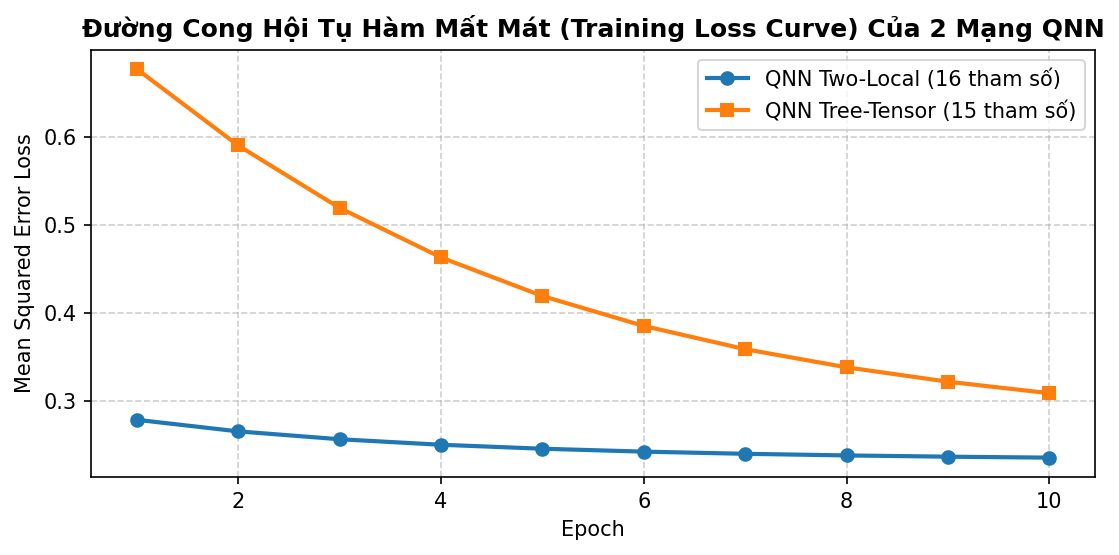

In [6]:
@qml.qnode(dev_8)
def qnn_twolocal_circuit(weights, x):
    qml.AngleEmbedding(x, wires=range(N_QUBITS))
    QNNTwoLocal(N_QUBITS, weights, repetitions=1)
    return qml.expval(qml.PauliZ(0))

@qml.qnode(dev_8)
def qnn_ttn_circuit(weights, x):
    qml.AngleEmbedding(x, wires=range(N_QUBITS))
    QNNTreeTensor(K_TTN, weights)
    return qml.expval(qml.PauliZ(0))

def cost_fn(circuit, weights, X, Y):
    preds_exp = pnp.stack([circuit(weights, x) for x in X])
    return pnp.mean((preds_exp - Y) ** 2)

sub_X_tr = pnp.array(xs_tr[:40], requires_grad=False)
sub_Y_tr = pnp.array(np.where(y_tr[:40] == 0, -1.0, 1.0), requires_grad=False)
EPOCHS = 10

# 6. Huấn luyện QNN (Two-Local + Angle)
print("[6/7] Đang huấn luyện QNN (Two-Local + Angle 8-Qubit, 16 tham số)...")
np.random.seed(RANDOM_SEED)
weights_tl = pnp.random.uniform(0, np.pi, size=(16,), requires_grad=True)
opt_tl = qml.GradientDescentOptimizer(stepsize=0.18)
loss_history_tl = []

t0 = time.time()
for ep in range(EPOCHS):
    weights_tl, cost_val = opt_tl.step_and_cost(lambda w: cost_fn(qnn_twolocal_circuit, w, sub_X_tr, sub_Y_tr), weights_tl)
    loss_history_tl.append(float(cost_val))
tr_time_tl = time.time() - t0
tr_preds_tl = np.where(np.array([float(qnn_twolocal_circuit(weights_tl, x)) for x in xs_tr]) >= 0.0, 1, 0)
tr_acc_tl = accuracy_score(y_tr, tr_preds_tl)
train_records.append({
    "Model": "QNN (Two-Local + Angle)",
    "Type": "Quantum NN",
    "Qubits": 8,
    "Architecture": "16 RY params, 7 ladder CNOTs",
    "Train Accuracy": round(tr_acc_tl, 4),
    "Train Time (s)": round(tr_time_tl, 4)
})
print(f"      Hoàn tất QNN Two-Local   | Train Acc = {tr_acc_tl:.4f} | Final Loss = {loss_history_tl[-1]:.4f} | Time = {tr_time_tl:.2f}s")

# 7. Huấn luyện QNN (Tree-Tensor + Angle)
print("[7/7] Đang huấn luyện QNN (Tree-Tensor + Angle 8-Qubit, 15 tham số)...")
np.random.seed(RANDOM_SEED)
weights_ttn = pnp.random.uniform(0, np.pi, size=(15,), requires_grad=True)
opt_ttn = qml.GradientDescentOptimizer(stepsize=0.18)
loss_history_ttn = []

t0 = time.time()
for ep in range(EPOCHS):
    weights_ttn, cost_val = opt_ttn.step_and_cost(lambda w: cost_fn(qnn_ttn_circuit, w, sub_X_tr, sub_Y_tr), weights_ttn)
    loss_history_ttn.append(float(cost_val))
tr_time_ttn = time.time() - t0
tr_preds_ttn = np.where(np.array([float(qnn_ttn_circuit(weights_ttn, x)) for x in xs_tr]) >= 0.0, 1, 0)
tr_acc_ttn = accuracy_score(y_tr, tr_preds_ttn)
train_records.append({
    "Model": "QNN (Tree-Tensor + Angle)",
    "Type": "Quantum NN",
    "Qubits": 8,
    "Architecture": "15 RY params, 7 binary-tree CNOTs",
    "Train Accuracy": round(tr_acc_ttn, 4),
    "Train Time (s)": round(tr_time_ttn, 4)
})
print(f"      Hoàn tất QNN Tree-Tensor | Train Acc = {tr_acc_ttn:.4f} | Final Loss = {loss_history_ttn[-1]:.4f} | Time = {tr_time_ttn:.2f}s")

plt.figure(figsize=(7.5, 3.8), dpi=150)
plt.plot(range(1, EPOCHS + 1), loss_history_tl, marker='o', lw=2, label="QNN Two-Local (16 tham số)")
plt.plot(range(1, EPOCHS + 1), loss_history_ttn, marker='s', lw=2, label="QNN Tree-Tensor (15 tham số)")
plt.title("Đường Cong Hội Tụ Hàm Mất Mát (Training Loss Curve) Của 2 Mạng QNN", fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---
## BƯỚC 6: Lưu Trữ Toàn Bộ Model & Trọng Số Lượng Tử Đã Huấn Luyện (`models/trained_qml_ddos_bundle.pkl`)

In [7]:
df_train_summary = pd.DataFrame(train_records)
print("=" * 95)
print("BẢNG TỔNG KẾT GIAI ĐOẠN HUẤN LUYỆN (TRAINING SUMMARY - 7 MÔ HÌNH)")
print("=" * 95)
print(df_train_summary.to_string(index=False))
print("=" * 95)

bundle_path = os.path.join(MODELS_DIR, "trained_qml_ddos_bundle.pkl")
trained_bundle = {
    "scaler": scaler,
    "pca": pca,
    "xs_tr": xs_tr,
    "y_tr": y_tr,
    "csvm": csvm,
    "cann": cann,
    "qsvm_angle": qsvm_angle,
    "qsvm_amp": qsvm_amp,
    "qsvm_zz": qsvm_zz,
    "states_tr_angle": states_tr_angle,
    "states_tr_amp": states_tr_amp,
    "states_tr_zz": states_tr_zz,
    "dt_angle": dt_angle,
    "dt_amp": dt_amp,
    "dt_zz": dt_zz,
    "weights_tl": np.array(weights_tl, dtype=float),
    "weights_ttn": np.array(weights_ttn, dtype=float),
    "loss_history_tl": loss_history_tl,
    "loss_history_ttn": loss_history_ttn,
    "train_summary": df_train_summary
}
joblib.dump(trained_bundle, bundle_path)
print(f"\n[SAVED SUCCESS] Đã đóng gói và lưu toàn bộ 7 mô hình đã huấn luyện tại: {bundle_path}")

BẢNG TỔNG KẾT GIAI ĐOẠN HUẤN LUYỆN (TRAINING SUMMARY - 7 MÔ HÌNH)
                    Model        Type  Qubits                          Architecture  Train Accuracy  Train Time (s)
      Classical SVM (RBF)   Classical       0                    RBF Kernel (C=1.0)          1.0000          0.0045
      Classical ANN (MLP)   Classical       0           MLP 8x8x16x8x1 (361 params)          1.0000          0.2009
   QSVM (Angle Embedding) Quantum SVM       8          8 RX gates (Depth=2, 0 CNOT)          1.0000         25.6854
 QSVM (Amplitude 3-Qubit) Quantum SVM       3 MottonenStatePrep (Depth=18, 14 CNOT)          0.9917         49.4590
    QSVM (ZZ Feature Map) Quantum SVM       8  28 CZ-RZ-CZ pairs (Depth=88, 112 CZ)          0.9833        190.5503
  QNN (Two-Local + Angle)  Quantum NN       8          16 RY params, 7 ladder CNOTs          0.9917          9.9853
QNN (Tree-Tensor + Angle)  Quantum NN       8     15 RY params, 7 binary-tree CNOTs          0.9917         10.0664

[SAVE